# Session 9b — What the model actually sees
**Tokens · cost · the context window · embeddings**

Run every cell top to bottom (Kernel → Restart & Run All). Each section ends with a question in *italics* — answer it in the reflection at the end.

Before starting: `git pull` and `uv sync` in the course repo, and open this notebook with `uv run jupyter lab` (or in VS Code with the project's `.venv` selected).

## 1. Setup — two providers, one client library
A **provider** is *where* the model runs; a **model** is *which brain* answers. The same client library talks to both — only `base_url` changes. We use Groq (from `.env`) for chat and Ollama (on your laptop) for embeddings.

In [1]:
import sys; sys.path[:0] = [".", "module01", "../module01"]
from tokens_utils import *          # count_tokens, show_tokens, cost_inr, chat_client, ollama_client, usage_for, load_points, WORDS
import os
MODEL = os.getenv("MODEL")
groq = chat_client()                # Groq — from .env
ollama = ollama_client()            # local — http://localhost:11434/v1
print("chat model:", MODEL)

chat model: openai/gpt-oss-20b


## 2. What a token is
A **tokenizer** is a fixed dictionary that splits text into pieces the model can read. The pieces are **tokens** — roughly ¾ of an English word each. The dictionary was built mostly from English and code, so other scripts cost more.

Our default model (`openai/gpt-oss-20b`) uses the `o200k_harmony` encoding, which `tiktoken` ships — so for this model the count is **exact**. For other models it is an estimate; the model's own `usage` field is the truth after you send (section 3).

In [2]:
TEXTS = {
    "english": "Can I get a personal loan of 8 lakh rupees for five years?",
    "telugu" :  "నాకు ఐదు సంవత్సరాలకు 8 లక్షల రూపాయల వ్యక్తిగత రుణం లభిస్తుందా?",
    "python" :  "def emi(p, r, n):\n    r = r/12/100\n    return p*r*(1+r)**n/((1+r)**n-1)",
    "json"   :  '{"pan": "ABCDE1234F", "amount": 800000, "tenure_months": 60}',
    "csv"    :  "pan,amount,tenure_months\nABCDE1234F,800000,60",

    # more Indian languages: same meaning as the English sentence
    "hindi"   :    "क्या मुझे पाँच साल के लिए 8 लाख रुपये का पर्सनल लोन मिल सकता है?",
    "tamil"   :    "எனக்கு ஐந்து ஆண்டுகளுக்கு 8 லட்சம் ரூபாய் தனிநபர் கடன் கிடைக்குமா?",
    "kannada" :  "ನನಗೆ ಐದು ವರ್ಷಗಳಿಗೆ 8 ಲಕ್ಷ ರೂಪಾಯಿ ವೈಯಕ್ತಿಕ ಸಾಲ ಸಿಗುತ್ತದೆಯೇ?",
    "bengali" :  "আমি কি পাঁচ বছরের জন্য ৮ লাখ টাকার ব্যক্তিগত ঋণ পেতে পারি?",

    # same languages typed in English letters (how people really chat)
    "hinglish"  : "Kya mujhe 5 saal ke liye 8 lakh ka personal loan mil sakta hai?",
    "tenglish"  : "Naaku aidu savatsaralaku 8 lakshala rupayala personal loan vastunda?",

    # structured and technical text
    "sql"   :  "SELECT customer_id, SUM(amount) FROM loans WHERE status = 'ACTIVE' GROUP BY customer_id;",
    "url"   :  "https://www.examplebank.in/loans/personal?amount=800000&tenure=60&ref=app",
    "xml"   :  "<loan><pan>ABCDE1234F</pan><amount>800000</amount><tenure>60</tenure></loan>",

    # odd cases
    "numbers" :  "800000 1200000 45000 9876543210 123456789012",
    "emoji"   :    "Loan approved 🎉🎉🎉 ✅💰🏦",
    "caps"    :     "URGENT: YOUR LOAN APPLICATION HAS BEEN APPROVED. CONTACT US IMMEDIATELY.",
    "spaces"  :   "Loan          amount:          8,00,000          tenure:          5 years",
}

base = count_tokens(TEXTS["english"])
print(f"{'text':9} {'chars':>6} {'tokens':>7} {'chars/token':>12} {'vs English':>11}")
for name, t in sorted(TEXTS.items(), key=lambda kv: -count_tokens(kv[1])):
    n = count_tokens(t)
    print(f"{name:9} {len(t):6d} {n:7d} {len(t)/n:12.1f} {n/base:10.1f}x")
    
    

print(f"{'text':8} {'chars':>6} {'tokens':>7} {'chars/token':>12}")
for name, t in TEXTS.items():
    n = count_tokens(t)
    print(f"{name:8} {len(t):6d} {n:7d} {len(t)/n:12.1f}")

text       chars  tokens  chars/token  vs English
python        71      35          2.0        2.2x
xml           76      29          2.6        1.8x
tamil         66      27          2.4        1.7x
telugu        62      25          2.5        1.6x
json          60      25          2.4        1.6x
url           73      25          2.9        1.6x
kannada       58      24          2.4        1.5x
hinglish      63      22          2.9        1.4x
tenglish      68      22          3.1        1.4x
hindi         64      21          3.0        1.3x
bengali       58      20          2.9        1.2x
sql           88      20          4.4        1.2x
caps          72      20          3.6        1.2x
numbers       44      19          2.3        1.2x
csv           45      18          2.5        1.1x
spaces        73      18          4.1        1.1x
english       58      16          3.6        1.0x
emoji         21      13          1.6        0.8x
text      chars  tokens  chars/token
english      

In [3]:
# See the pieces. Where does the tokenizer cut?
for name in ("english", "telugu"):
    print(name, "→", show_tokens(TEXTS[name]), "\n")

english → ['Can', ' I', ' get', ' a', ' personal', ' loan', ' of', ' ', '8', ' lakh', ' ru', 'pees', ' for', ' five', ' years', '?'] 

telugu → ['న', 'ాకు', ' ఐ', 'దు', ' సంవత్సర', 'ాలకు', ' ', '8', ' లక్ష', 'ల', ' రూప', 'ాయ', 'ల', ' వ్యక్త', 'ిగ', 'త', ' ర', 'ుణ', 'ం', ' ల', 'భ', 'ిస్త', 'ుంద', 'ా', '?'] 



*Question 1 — The Telugu sentence means the same as the English one. Why does it cost more tokens, and what does that mean for a bank whose customers write in Telugu?*

## 3. Check against reality — the `usage` field
Send the same texts to a real model and read `usage.prompt_tokens`. The model adds a few *template tokens* around your message (role markers), so expect the real number to be slightly higher than the raw count. If Ollama is running, send them there too — a **different model, a different tokenizer, a different count**.

In [4]:
import os
from dotenv import load_dotenv
from groq import Groq

# 1. Load your .env file variables
load_dotenv()

# 2. Initialize the groq client using your saved key
groq = Groq(api_key=os.environ.get("GROQ_API_KEY"))

# 3. Ensure your MODEL variable is defined if not already done
MODEL = os.environ.get("MODEL", "openai/gpt-oss-20b")

In [5]:
def usage(client, model, text):
    return usage_for(client, model, text)[0]

overhead_groq = usage(groq, MODEL, "hi") - count_tokens("hi")
print(f"template wrapper on Groq/{MODEL}: {overhead_groq} tokens you never typed\n")
print(f"{'text':8} {'tiktoken':>9} {'groq usage':>11} {'minus wrapper':>14} {'ollama usage':>13}")
for name, t in TEXTS.items():
    est = count_tokens(t)
    g = usage(groq, MODEL, t)
    try:
        o = str(usage(ollama, "llama3.2:3b", t))
    except Exception:
        o = "(no ollama)"
    print(f"{name:8} {est:9d} {g:11d} {g - overhead_groq:14d} {o:>13}")

template wrapper on Groq/openai/gpt-oss-20b: 71 tokens you never typed

text      tiktoken  groq usage  minus wrapper  ollama usage
english         16          87             16            41
telugu          25          96             25           132
python          35         106             35            61
json            25          96             25            49
csv             18          89             18            42
hindi           21          92             21            60
tamil           27          98             27           114
kannada         24          95             24           124
bengali         20          91             20            92
hinglish        22          93             22            47
tenglish        22          93             22            48
sql             20          91             20            45
url             25          96             25            49
xml             29         100             29            54
numbers         19          

*Question 2 — Tokens are a property of the model, not the text. Which row shows this most clearly?*

## 4. What it costs
Providers charge per token, in and out, per million. The price cards below are **indicative** — edit them from the provider's pricing page. We convert to ₹ and scale to 1,000 calls, because a chatbot does not answer once.

In [6]:
for card in PRICE_CARDS:
    print(f"\n{card}")
    for name, t in TEXTS.items():
        p_in = count_tokens(t); p_out = 120          # assume a 120-token answer
        print(f"  {name:8} ₹{cost_inr(p_in, p_out, card):8.4f} per call   ₹{cost_inr(p_in, p_out, card, calls=1000):8.2f} per 1,000 calls")


groq gpt-oss-20b
  english  ₹  0.0031 per call   ₹    3.12 per 1,000 calls
  telugu   ₹  0.0032 per call   ₹    3.18 per 1,000 calls
  python   ₹  0.0032 per call   ₹    3.24 per 1,000 calls
  json     ₹  0.0032 per call   ₹    3.18 per 1,000 calls
  csv      ₹  0.0031 per call   ₹    3.14 per 1,000 calls
  hindi    ₹  0.0032 per call   ₹    3.16 per 1,000 calls
  tamil    ₹  0.0032 per call   ₹    3.19 per 1,000 calls
  kannada  ₹  0.0032 per call   ₹    3.18 per 1,000 calls
  bengali  ₹  0.0031 per call   ₹    3.15 per 1,000 calls
  hinglish ₹  0.0032 per call   ₹    3.16 per 1,000 calls
  tenglish ₹  0.0032 per call   ₹    3.16 per 1,000 calls
  sql      ₹  0.0031 per call   ₹    3.15 per 1,000 calls
  url      ₹  0.0032 per call   ₹    3.18 per 1,000 calls
  xml      ₹  0.0032 per call   ₹    3.21 per 1,000 calls
  numbers  ₹  0.0031 per call   ₹    3.14 per 1,000 calls
  emoji    ₹  0.0031 per call   ₹    3.11 per 1,000 calls
  caps     ₹  0.0031 per call   ₹    3.15 per 1,000 ca

*Question 3 — Output tokens cost more than input tokens on every card. What does that suggest about how you should ask a model to answer?*

## 5. The context window as a budget
A model sees a fixed number of tokens at once — its **context window**. Everything must fit: your system prompt, the whole conversation so far, any documents you paste in, any tool results. Here we simulate a growing conversation and watch the count climb. Where the line crosses the limit, something has to be dropped — that is Session 19's problem (memory windows) and Session 38's (context engineering).

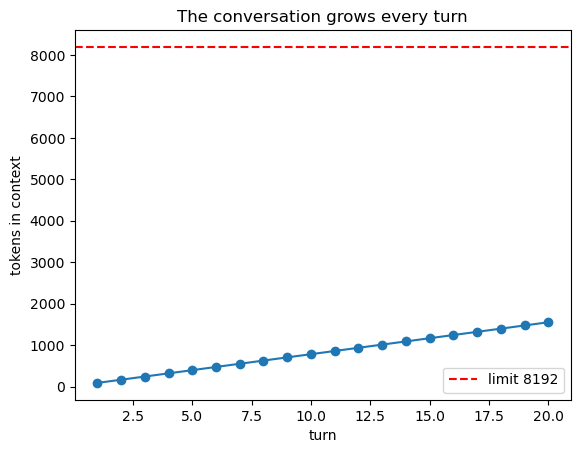

tokens at turn 20: 1550


In [7]:
import matplotlib.pyplot as plt
system = "You are a concise assistant for a retail bank."
history = [{"role": "system", "content": system}]
totals = []
for turn in range(1, 21):
    history.append({"role": "user", "content": f"Turn {turn}: {TEXTS['english']}"})
    history.append({"role": "assistant", "content": "Certainly. " + "Here is a detailed answer about your loan. " * 6})
    totals.append(sum(count_tokens(m["content"]) for m in history))
LIMIT = 8192   # a small window, for the picture; real models are far larger — but so are real conversations with documents
plt.plot(range(1, 21), totals, marker="o"); plt.axhline(LIMIT, color="red", linestyle="--", label=f"limit {LIMIT}")
plt.xlabel("turn"); plt.ylabel("tokens in context"); plt.title("The conversation grows every turn"); plt.legend(); plt.show()
print("tokens at turn 20:", totals[-1])

*Question 4 — At turn 21, what is in the window and what has to go? Who decides?*

## 6. Embeddings — meaning as coordinates
An **embedding model** does not answer. It turns text into a **vector** — a list of numbers (768 here) — such that similar meanings land close together. We embed ten words with a local model, squash 768 dimensions to 2 with PCA (plain NumPy), and draw them. If Ollama is not running, the notebook loads a cached copy made with the same model.

Where this comes back: **Module 4** (vector databases), **Module 5** (RAG), **Session 39** (agentic RAG).

source: ollama:nomic-embed-text


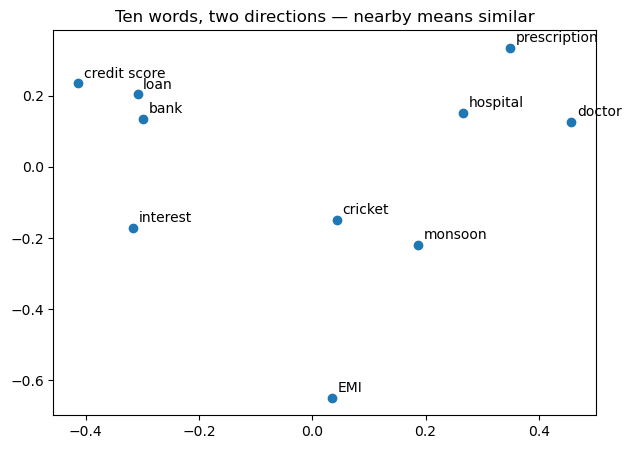

In [8]:
pts, source = load_points(WORDS)
print("source:", source)
plt.figure(figsize=(7, 5))
plt.scatter(pts[:, 0], pts[:, 1])
for w, (x, y) in zip(WORDS, pts):
    plt.annotate(w, (x, y), xytext=(4, 4), textcoords="offset points")
plt.title("Ten words, two directions — nearby means similar"); plt.show()

*Question 5 — Which words cluster? Which word sits alone, and why? What can an embedding model **not** do?*

## 7. Reflection
Answer the five questions above here, one or two lines each.

1. Telugu costs more because the tokenizer was built mostly from English and code. Telugu characters aren’t common in that dictionary, so the text is cut into many small pieces. so it fills the context window about 3x faster.

2. If you compare the minus wrapper column (Groq/GPT tokenizer) to the ollama usage column (Llama tokenizer) for telugu, you can see a massive difference: it takes only 25 tokens in the GPT tokenizer, but 132 tokens in Ollama for the exact same piece of text. hence..tokens are defined by the model's tokenizer, not the text!, The best rows to point to for this answer are the Indic languages, such as telugu, kannada, tamil, or bengali.

3. By enforcing System messages that act as strict windows of rules, giving the model clear constraints, boundaries, and output limits.

4. Everything from turn 1 through turn 21 still fits inside the context window, so nothing has to go yet (since turn 20 was only ~1550 tokens, well below the 8192 limit).
The developer (you)—because the model does not manage its own memory; your Python code decides which past messages stay or get dropped before sending them to the API.

5. credit score, loan, bank is cluster. EMI sits everyone coz it could be anywhere. an embedding model can not give an result or the output, it's just convert the tokens into vector which is the mathematical forms of those particuler tokens, it's just puts words in vector which having or sharing the same meanning, and pushes apart the words doesn't have same meanings.

Then run the checkpoint from the terminal: `uv run pytest tests/test_s09.py`